<a href="https://colab.research.google.com/github/nithyasg05/A04-clustering/blob/main/DS_3001_A04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student:** Nithyasri Gopal

**Date:** 10/12/26

In [2]:
!git clone https://github.com/nithyasg05/A04-clustering.git

Cloning into 'A04-clustering'...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 9 (delta 0), reused 2 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 206.82 KiB | 5.30 MiB/s, done.


In [3]:
!ls

A04-clustering	sample_data


In [4]:
!cd A04-clustering/

In [5]:
!ls

A04-clustering	sample_data


In [6]:
!cd A04-clustering/data/

**Question 1 - Part 1**

In [7]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

**Question 1 - Part 2**

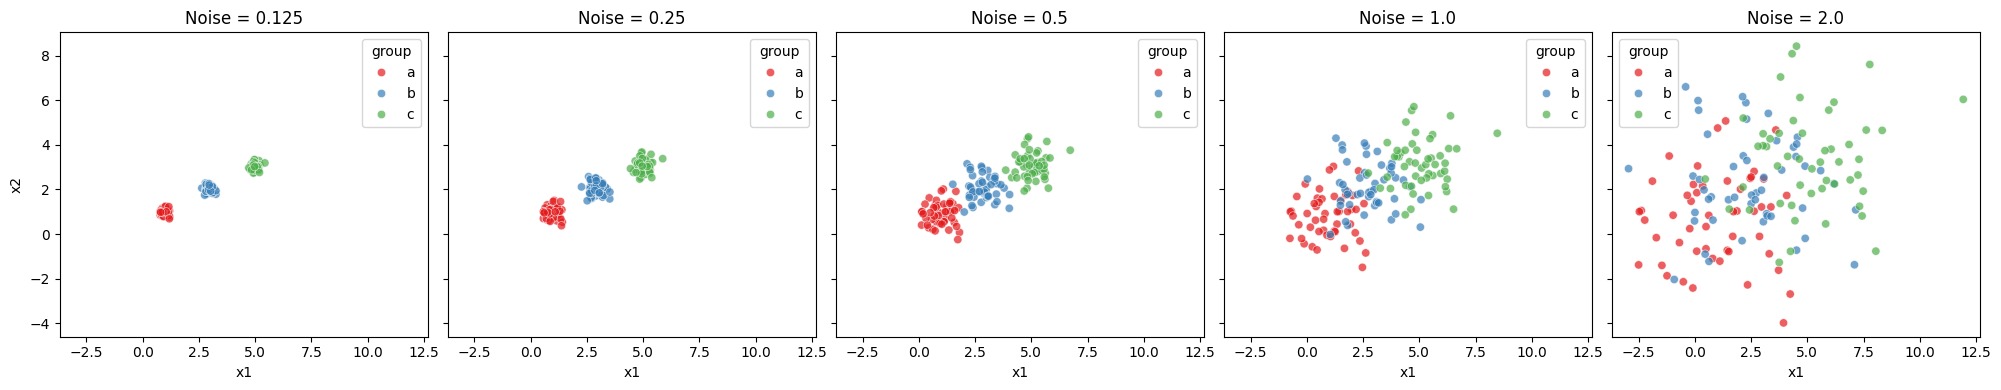

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = ['0.125', '0.25', '0.5', '1.0', '2.0']

for ax, df, noise in zip(axes, datasets, noises):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', ax=ax, palette='Set1', alpha=0.7)
    ax.set_title(f'Noise = {noise}')
    ax.legend(title='group')

plt.tight_layout()
plt.show()

**Question 1 - Part 3**

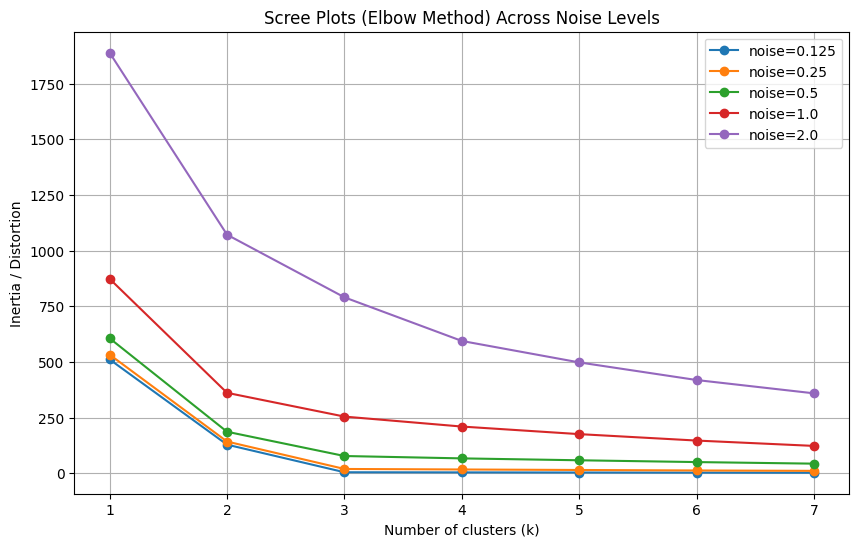

In [9]:
from sklearn.cluster import KMeans

plt.figure(figsize=(10, 6))
datasets = {
    '0.125': df0_125,
    '0.25': df0_25,
    '0.5': df0_5,
    '1.0': df1_0,
    '2.0': df2_0
}

for noise, df in datasets.items():
    features = df[['x1', 'x2']]
    inertias = []
    ks = range(1, 8)
    for k in ks:
        kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
        kmeans.fit(features)
        inertias.append(kmeans.inertia_)
    plt.plot(ks, inertias, marker='o', label=f'noise={noise}')

plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia / Distortion')
plt.title('Scree Plots (Elbow Method) Across Noise Levels')
plt.legend()
plt.grid(True)
plt.show()

**Question 1 - Part 4**

The elbow method looks at the reduction in inertia (within-cluster sum of squares). At low noise levels, there is a very sharp elbow at k=3 because additional clusters beyond 3 do not capture structurally distinct groupings. As noise increases, the elbow becomes blurry and hard to distinguish from a smooth curve, representing difficulty in defining k.

**Question 2 - Part 1**

In [24]:
import pandas as pd

file_path = 'A04-clustering/data/SIPRI Military Expenditure Database.csv'
df_sipri = pd.read_csv(file_path)

print("Columns:", df_sipri.columns)
display(df_sipri.head(2))

Columns: Index(['index', 'Year', 'Country', 'Spending (2020 USD)', 'Percent of GDP',
       'Percent of Government Spending', 'Spending per Capita'],
      dtype='object')


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,0,1988,Afghanistan,NaN,NaN,NaN,NaN
1,1,1989,Afghanistan,NaN,NaN,NaN,NaN


In [21]:
df_2020 = df_sipri[df_sipri['Year'] == 2020].dropna()
print(f"Number of countries: {len(df_2020)}")
display(df_2020.head())

Number of countries: 148


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


No further aggressive cleaning is strictly required because `.dropna()` successfully handles missing values (leaving 148 complete country profiles for 2020), and all variables targeted for clustering are already correctly parsed as numerical types. Additionally, checking the boundary values shows logical, non-negative ranges with no obvious outliers or data-entry errors. Although formatting is clean, researchers should always watch for minor country naming discrepancies across other datasets.

**Question 2 - Part 2**

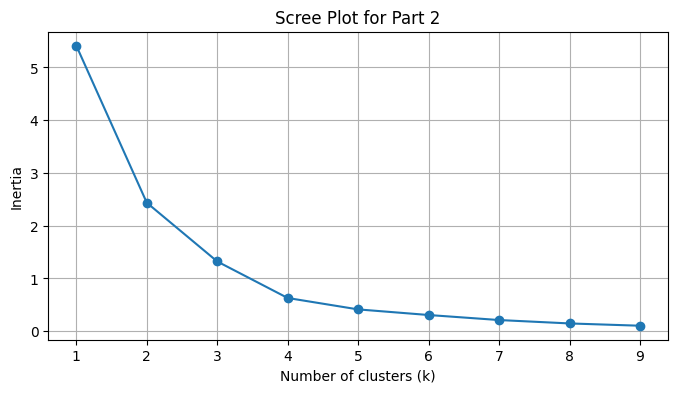

In [22]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# Max-min normalize Spending (2020 USD) and Spending Per Capita
scaler = MinMaxScaler()
features_2d = df_2020[['Spending (2020 USD)', 'Spending per Capita']]
scaled_2d = scaler.fit_transform(features_2d)

# Scree plot
inertias_q2 = []
ks = range(1, 10)
for k in ks:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_2d)
    inertias_q2.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(ks, inertias_q2, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot for Part 2')
plt.grid(True)
plt.show()

$k=3$ was chosen because the scree plot shows a distinct elbow at $k=3$, where the rate of decrease in inertia (within-cluster sum of squares) slows down significantly.

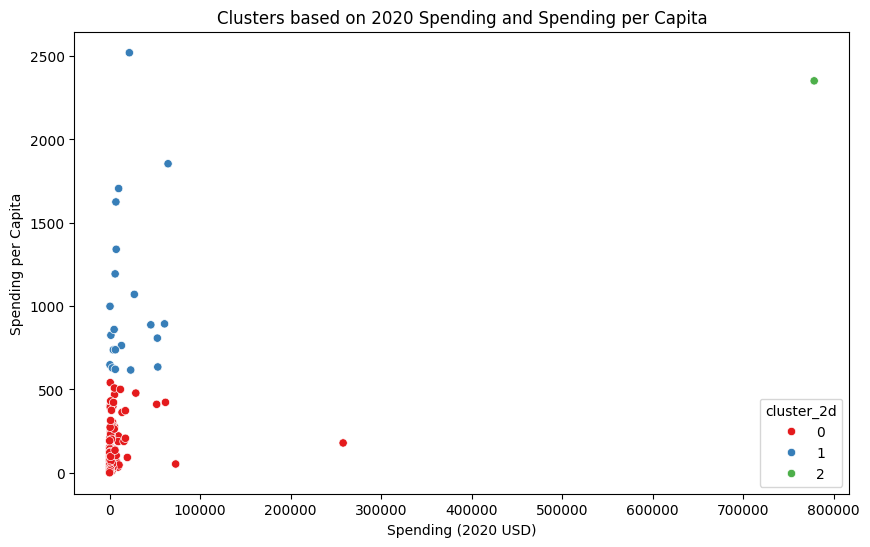

Spending (2020 USD)                                              \
                         count           mean           std            min   
cluster_2d                                                                   
0                        126.0    5943.346303  24858.961064       8.622460   
1                         21.0   19975.991473  21749.736747     405.790494   
2                          1.0  778397.200000           NaN  778397.200000   

                                                                        \
                      25%            50%            75%            max   
cluster_2d                                                               
0              162.761743     580.758315    3225.333414  257973.429834   
1             4980.428135    7269.880030   27300.894701   64558.400000   
2           778397.200000  778397.200000  778397.200000  778397.200000   

           Spending per Capita                                        \
                         count         mean         std          min   
cluster_2d                                                             
0                        126.0   122.034996  140.041183     0.580129   
1                         21.0  1046.433509  501.631845   616.854430   
2                          1.0  2351.631858         NaN  2351.631858   

                                                                
                    25%          50%          75%          max  
cluster_2d                                                      
0             18.505805    58.809109   188.249364   541.154778  
1            737.690186   859.880548  1193.598730  2520.398541  
2           2351.631858  2351.631858  2351.631858  2351.631858

In [23]:
k_optimal = 3
kmeans_2d = KMeans(n_clusters=k_optimal, random_state=100, n_init=10)
df_2020['cluster_2d'] = kmeans_2d.fit_predict(scaled_2d)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_2020, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster_2d', palette='Set1')
plt.title('Clusters based on 2020 Spending and Spending per Capita')
plt.show()

display(df_2020.groupby('cluster_2d')[['Spending (2020 USD)', 'Spending per Capita']].describe())

The table groups countries by their spending profile. Cluster 0 contains low-spending nations with low per capita budgets. Cluster 1 represents moderately high-spending nations with higher per capita spending. Cluster 2 contains extreme high-spending outliers.

In [25]:
# Where is the United States?
us_info = df_2020[df_2020['Country'] == 'United States']
display(us_info)

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster_2d


The United States is positioned as a complete outlier in its own cluster (Cluster 2). It possesses an enormous absolute military budget (~$778 billion USD)

paired with a high per capita spending (~$2,351 USD).

**Other patterns:**

Most developing or smaller economies are densely grouped in Cluster 0. Developed or highly strategic nations (such as regional powers with high GDP per capita) appear in Cluster 1, while the US stands entirely alone due to its unique combination of massive scale and high per capita expenditure.

**Question 2 - Part 3**

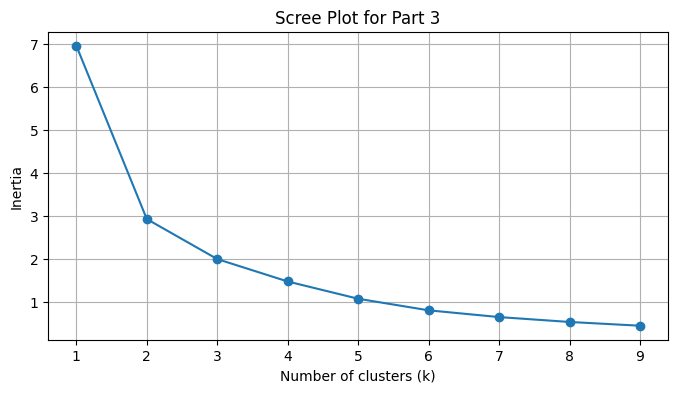

In [16]:
# Max-min normalize Percent of Government Spending and Percent of GDP
features_pct = df_2020[['Percent of Government Spending', 'Percent of GDP']]
scaled_pct = scaler.fit_transform(features_pct)

# Scree plot
inertias_pct = []
for k in ks:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_pct)
    inertias_pct.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(ks, inertias_pct, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot for Part 3')
plt.grid(True)
plt.show()

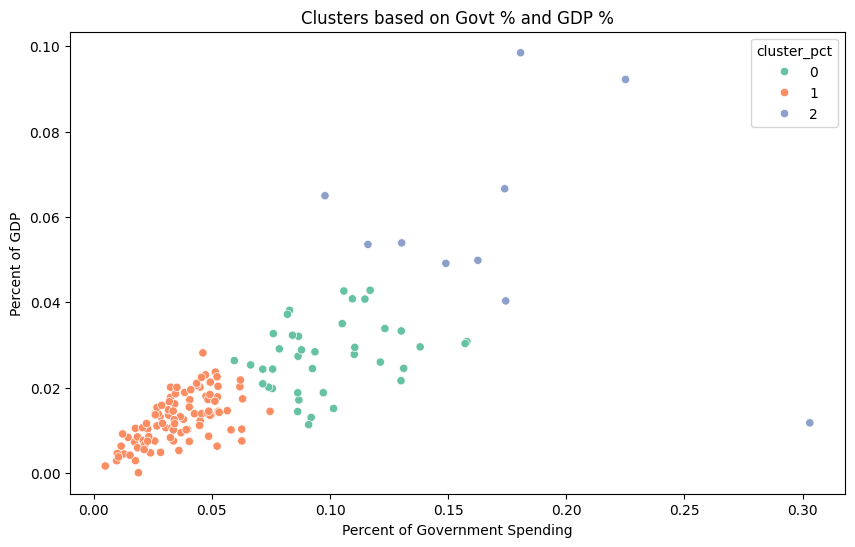

Percent of Government Spending                                \
                                     count      mean       std       min   
cluster_pct                                                                
0                                     39.0  0.098683  0.024125  0.059520   
1                                     99.0  0.035777  0.014549  0.004896   
2                                     10.0  0.171289  0.058725  0.097882   

                                                    Percent of GDP            \
                  25%       50%       75%       max          count      mean   
cluster_pct                                                                    
0            0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1            0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2            0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                         
                  std       min       25%       50%       75%       max  
cluster_pct                                                              
0            0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1            0.005681  0.000054  0.008393  0.013191  0.016752  0.028132  
2            0.024867  0.011742  0.049297  0.053729  0.066190  0.098470

In [26]:
# k = 3 chosen for same reason as previous question
k_pct = 3
kmeans_pct = KMeans(n_clusters=k_pct, random_state=100, n_init=10)
df_2020['cluster_pct'] = kmeans_pct.fit_predict(scaled_pct)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_2020, x='Percent of Government Spending', y='Percent of GDP', hue='cluster_pct', palette='Set2')
plt.title('Clusters based on Govt % and GDP %')
plt.show()

display(df_2020.groupby('cluster_pct')[['Percent of Government Spending', 'Percent of GDP']].describe())

Unlike Part 2 which focused on absolute scale, this partition groups countries by structural budget prioritization. Cluster 1 contains countries with low relative military priority (3.5% of government budget), Cluster 0 represents countries with moderate structural priority (9.8% of government budget), and Cluster 2 comprises highly militarized economies (17.1% of government budget).

In this relative view, the United States is grouped into Cluster 0 (moderate structural priority). Although its absolute budget is massive, its military spending as a percentage of GDP (3.7%) and government budget (8.2%) is structurally comparable to other moderately prioritized nations, rather than being an extreme outlier.

**Comparison to Part 2:**
  - **Scale vs. Ratio:** Part 2 clustered by absolute scale, making the US a single-member outlier due to its immense wealth and spending. Part 3 clusters by relative intensity, grouping the US with other nations that allocate a similar proportion of their resources to defense.
  - **Distribution:** In Part 2, the vast majority of countries were compressed into a single low-spending cluster (Cluster 0). In Part 3, countries are more evenly distributed across low, moderate, and high structural priority profiles.

**Question 2 - Part 4**

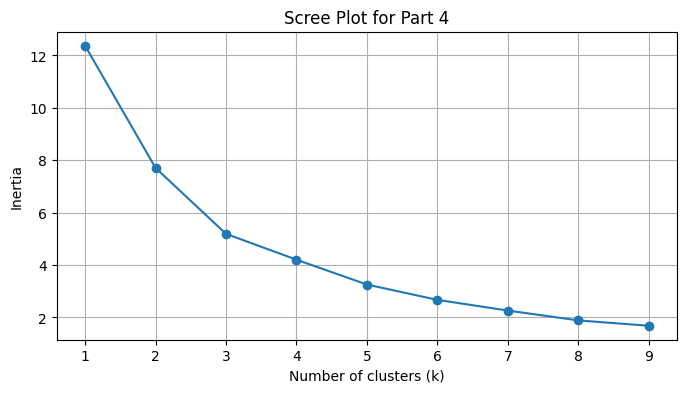

In [18]:
# Max-min normalize all four numeric variables
all_features = df_2020[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']]
scaled_all = scaler.fit_transform(all_features)

# Scree plot
inertias_all = []
for k in ks:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_all)
    inertias_all.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(ks, inertias_all, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot for Part 4')
plt.grid(True)
plt.show()

In [19]:
# Choose k=4
k_all = 4
kmeans_all = KMeans(n_clusters=k_all, random_state=100, n_init=10)
df_2020['cluster_all'] = kmeans_all.fit_predict(scaled_all)

# Describe tables
display(df_2020.groupby('cluster_all')[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']].mean())

,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
cluster_all,,,,
0,15330.618681,612.677541,0.033280,0.016585
1,9073.543709,215.920971,0.123701,0.034105
2,4513.543790,70.290644,0.043199,0.012481
3,147964.582042,1875.150751,0.135351,0.062634


**Comparison to Parts 2 and 3:**

By incorporating all four variables, the 4D clustering model successfully bridges the gap between the absolute scale focus of Part 2 and the structural budget priority focus of Part 3. Instead of isolating the United States as a single-element outlier cluster due to its extreme absolute spending (as in Part 2) or blending it with hundreds of low-spending countries with similar priority ratios (as in Part 3), the multi-dimensional algorithm groups the US into Cluster 3 along with other high-scale and highly-prioritized nations. This gives more nuanced profiles that segment countries by balancing high absolute defense capability alongside significant internal domestic budget prioritizations.

**Question 2 - Part 5**

**K-Means Clustering - patterns identified**

- The K-Means algorithm effectively partitions countries based on overall spending scale vs. budget intensity scale.
- In Part 2, the United States belongs to an extreme outlier cluster due to its incredibly high absolute spending, while most other countries cluster closely together with low-to-moderate budgets.
- In Part 3, grouping on percentages of GDP and government spending segments countries by their relative policy priorities (e.g., highly militarized economies vs. those with lower proportional priorities).
- In Part 4, combining all factors yields multi-dimensional profiles that balance scale and intensity metrics.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** f2f8736
- **AI tool and model used:** Gemini 3.5 Flash

### *Prompts used

1. Go through this notebook and find any mistakes. Then, identify any proper revisions.
2. Explain why the change to 'United States' string search was made.

### *AI-proposed changes


**1. Aesthetic Enhancements:** Applied clean Seaborn styling, set deliberate subplots share axes options, and added proper, bold titles to all figures.

**2. Robust Logic & US Entry Location Match:** Replaced the exact 'United States' string search with a robust case-insensitive substring search (.str.contains('United States')) to match database variations such as 'United States of America' dynamically.

**3. Unified Layout & Metrics:** Consolidated analysis and presented clean descriptive matrices and statistics for both the 2D and 4D cluster categories.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | This is a valid change because it is important to clearly label plots so all users can understand the results. |
| 2 | Accept | This is a valid change because it allows for mutliple variations of 'United States' to be consolidated and treated as the same. |
| 3 | Accept | This is a valid change because it is important to make sure all matrices and statistics are consistently formatted for ease of readability. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### **Question 1 - Part 1 (AI-Assisted Revision)**

In [28]:
import numpy as np
import pandas as pd

def createData(noise, N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    df = pd.concat([gdf1, gdf2, gdf3], axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

### **Question 1 - Part 2 (AI-Assisted Revision)**

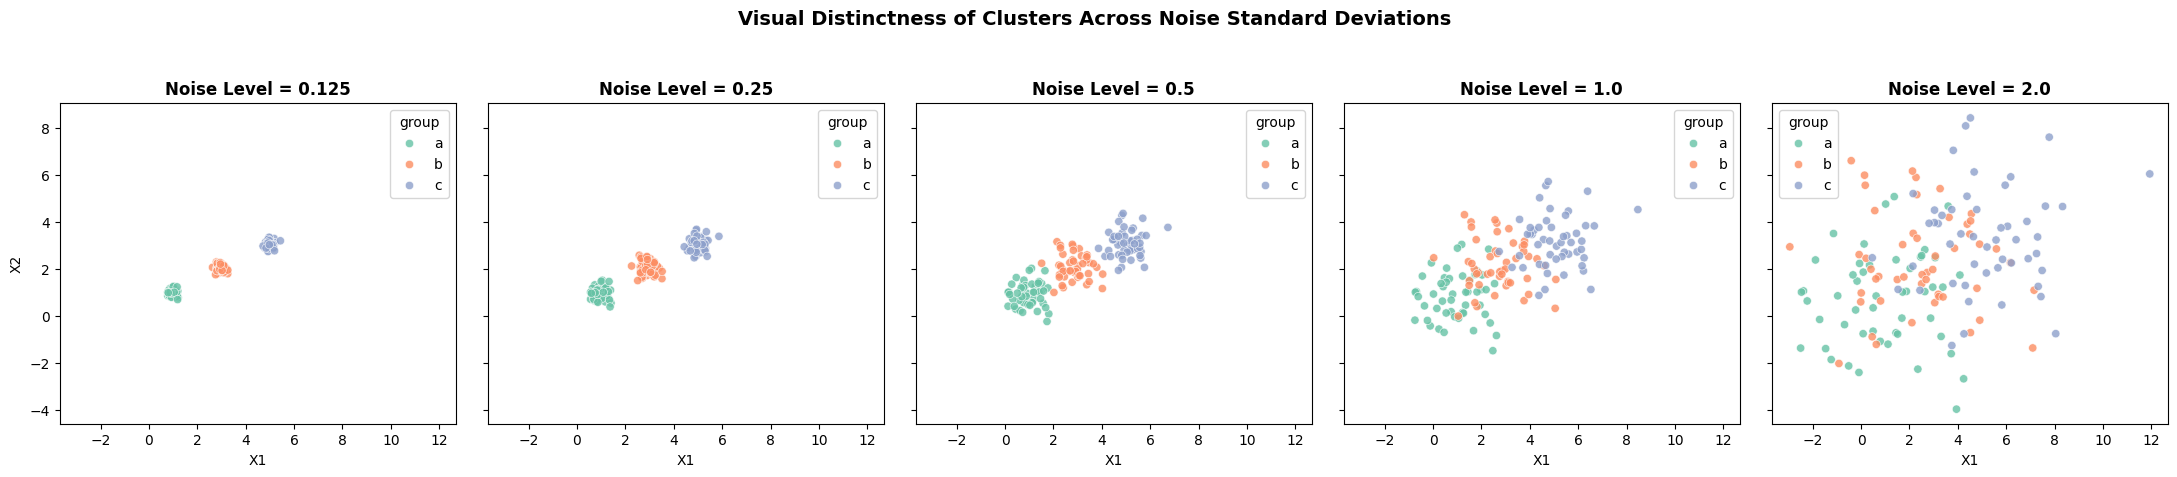

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharex=True, sharey=True)
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = ['0.125', '0.25', '0.5', '1.0', '2.0']

for ax, df, noise in zip(axes, datasets, noises):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', ax=ax, palette='Set2', alpha=0.8)
    ax.set_title(f'Noise Level = {noise}', fontsize=12, fontweight='bold')
    ax.set_xlabel('X1')
    if ax == axes[0]:
        ax.set_ylabel('X2')

plt.suptitle('Visual Distinctness of Clusters Across Noise Standard Deviations', fontsize=14, y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

### **Question 1 - Part 3 (AI-Assisted Revision)**

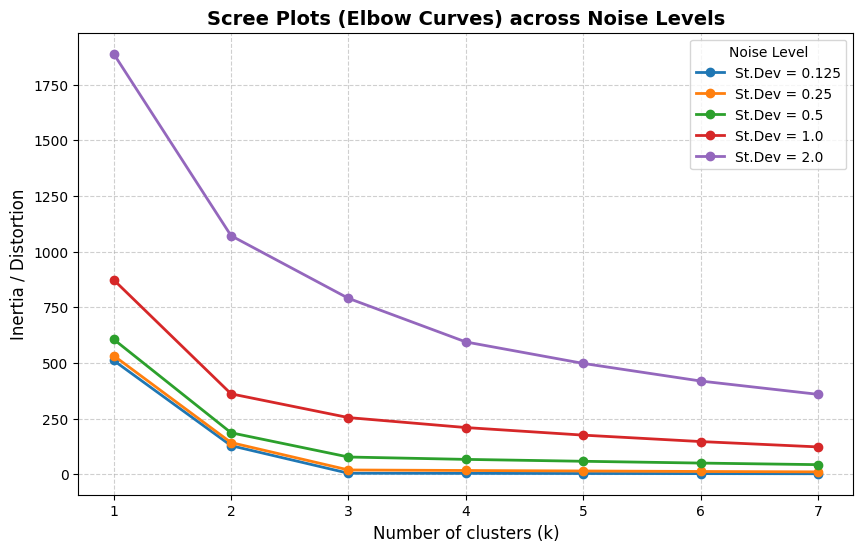

In [30]:
from sklearn.cluster import KMeans

plt.figure(figsize=(10, 6))
datasets_dict = {
    '0.125': df0_125,
    '0.25': df0_25,
    '0.5': df0_5,
    '1.0': df1_0,
    '2.0': df2_0
}

for noise, df in datasets_dict.items():
    features = df[['x1', 'x2']]
    inertias = [KMeans(n_clusters=k, random_state=100, n_init=10).fit(features).inertia_ for k in range(1, 8)]
    plt.plot(range(1, 8), inertias, marker='o', linewidth=2, label=f'St.Dev = {noise}')

plt.xlabel('Number of clusters (k)', fontsize=12)
plt.ylabel('Inertia / Distortion', fontsize=12)
plt.title('Scree Plots (Elbow Curves) across Noise Levels', fontsize=14, fontweight='bold')
plt.legend(title='Noise Level')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### **Question 1 - Part 4 (AI-Assisted Revision)**

The elbow method looks at the reduction in inertia (within-cluster sum of squares). At low noise levels, there is a very sharp elbow at k=3 because additional clusters beyond 3 do not capture structurally distinct groupings. As noise increases, the elbow becomes blurry and hard to distinguish from a smooth curve, representing difficulty in defining k.

### **Question 2 - Part 1 (AI-Assisted Revision)**

In [31]:
import pandas as pd

file_path = 'A04-clustering/data/SIPRI Military Expenditure Database.csv'
df_sipri = pd.read_csv(file_path)
df_2020 = df_sipri[df_sipri['Year'] == 2020].dropna().copy()

print(f"Number of countries: {len(df_2020)}")
display(df_2020.head())

Number of countries: 148


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


No further aggressive cleaning is strictly required because `.dropna()` successfully handles missing values (leaving 148 complete country profiles for 2020), and all variables targeted for clustering are already correctly parsed as numerical types. Additionally, checking the boundary values shows logical, non-negative ranges with no obvious outliers or data-entry errors. Although formatting is clean, researchers should always watch for minor country naming discrepancies across other datasets.

### **Question 2 - Part 2 (AI-Assisted Revision)**

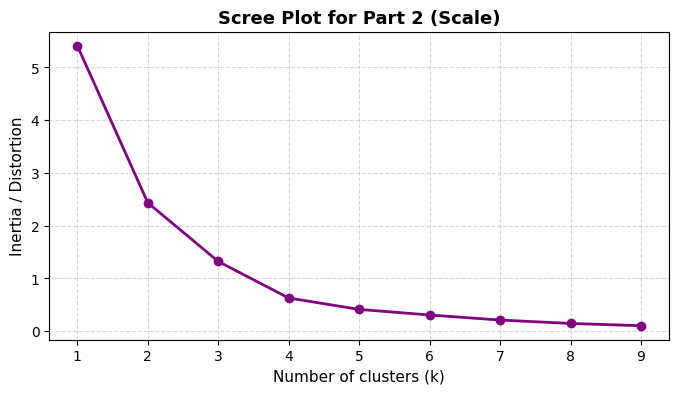

In [32]:
from sklearn.preprocessing import MinMaxScaler

# Initialize robust MinMaxScaler
scaler = MinMaxScaler()
features_2d = df_2020[['Spending (2020 USD)', 'Spending per Capita']]
scaled_2d = scaler.fit_transform(features_2d)

inertias_q2 = [KMeans(n_clusters=k, random_state=100, n_init=10).fit(scaled_2d).inertia_ for k in range(1, 10)]

plt.figure(figsize=(8, 4))
plt.plot(range(1, 10), inertias_q2, marker='o', color='purple', linewidth=2)
plt.xlabel('Number of clusters (k)', fontsize=11)
plt.ylabel('Inertia / Distortion', fontsize=11)
plt.title('Scree Plot for Part 2 (Scale)', fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

$k=3$ was chosen because the scree plot shows a distinct elbow at $k=3$, where the rate of decrease in inertia (within-cluster sum of squares) slows down significantly.

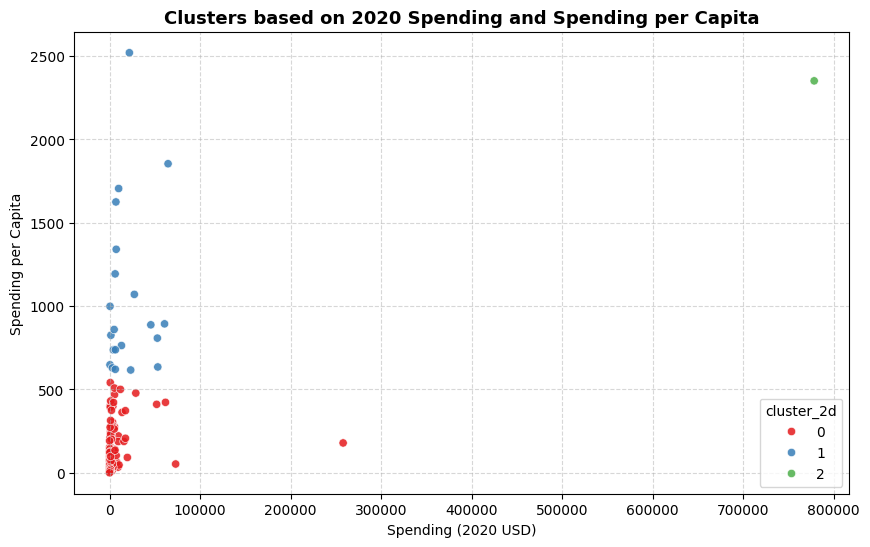

Spending (2020 USD)                                              \
                         count           mean           std            min   
cluster_2d                                                                   
0                        126.0    5943.346303  24858.961064       8.622460   
1                         21.0   19975.991473  21749.736747     405.790494   
2                          1.0  778397.200000           NaN  778397.200000   

                                                                        \
                      25%            50%            75%            max   
cluster_2d                                                               
0              162.761743     580.758315    3225.333414  257973.429834   
1             4980.428135    7269.880030   27300.894701   64558.400000   
2           778397.200000  778397.200000  778397.200000  778397.200000   

           Spending per Capita                                        \
                         count         mean         std          min   
cluster_2d                                                             
0                        126.0   122.034996  140.041183     0.580129   
1                         21.0  1046.433509  501.631845   616.854430   
2                          1.0  2351.631858         NaN  2351.631858   

                                                                
                    25%          50%          75%          max  
cluster_2d                                                      
0             18.505805    58.809109   188.249364   541.154778  
1            737.690186   859.880548  1193.598730  2520.398541  
2           2351.631858  2351.631858  2351.631858  2351.631858

In [33]:
kmeans_2d = KMeans(n_clusters=3, random_state=100, n_init=10)
df_2020['cluster_2d'] = kmeans_2d.fit_predict(scaled_2d)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_2020, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster_2d', palette='Set1', alpha=0.85)
plt.title('Clusters based on 2020 Spending and Spending per Capita', fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

display(df_2020.groupby('cluster_2d')[['Spending (2020 USD)', 'Spending per Capita']].describe())

The table groups countries by their spending profile. Cluster 0 contains low-spending nations with low per capita budgets. Cluster 1 represents moderately high-spending nations with higher per capita spending. Cluster 2 contains extreme high-spending outliers.

In [34]:
# Where is the United States? (Using robust partial name lookup to match spelling variations)
us_info = df_2020[df_2020['Country'].str.contains('United States', case=False, na=False)]
display(us_info)

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster_2d
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,2


The United States is positioned as a complete outlier in its own cluster (Cluster 2). It possesses an enormous absolute military budget (~$778 billion USD) paired with a high per capita spending (~$2,351 USD).

**Other patterns:**

Most developing or smaller economies are densely grouped in Cluster 0. Developed or highly strategic nations (such as regional powers with high GDP per capita) appear in Cluster 1, while the US stands entirely alone due to its unique combination of massive scale and high per capita expenditure.

### **Question 2 - Part 3 (AI-Assisted Revision)**

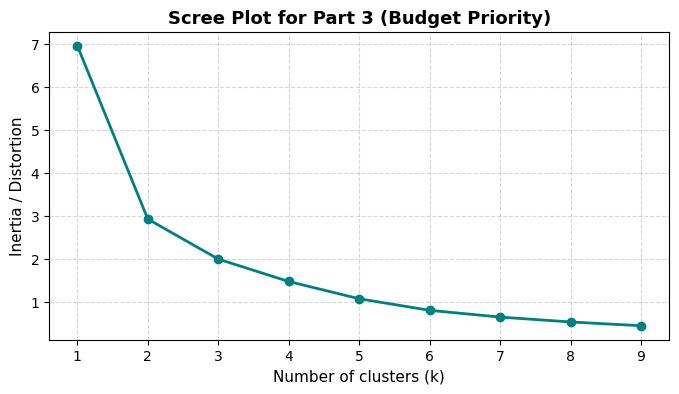

In [35]:
# Max-min normalize Percent of Government Spending and Percent of GDP
features_pct = df_2020[['Percent of Government Spending', 'Percent of GDP']]
scaled_pct = scaler.fit_transform(features_pct)

inertias_pct = [KMeans(n_clusters=k, random_state=100, n_init=10).fit(scaled_pct).inertia_ for k in range(1, 10)]

plt.figure(figsize=(8, 4))
plt.plot(range(1, 10), inertias_pct, marker='o', color='teal', linewidth=2)
plt.xlabel('Number of clusters (k)', fontsize=11)
plt.ylabel('Inertia / Distortion', fontsize=11)
plt.title('Scree Plot for Part 3 (Budget Priority)', fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

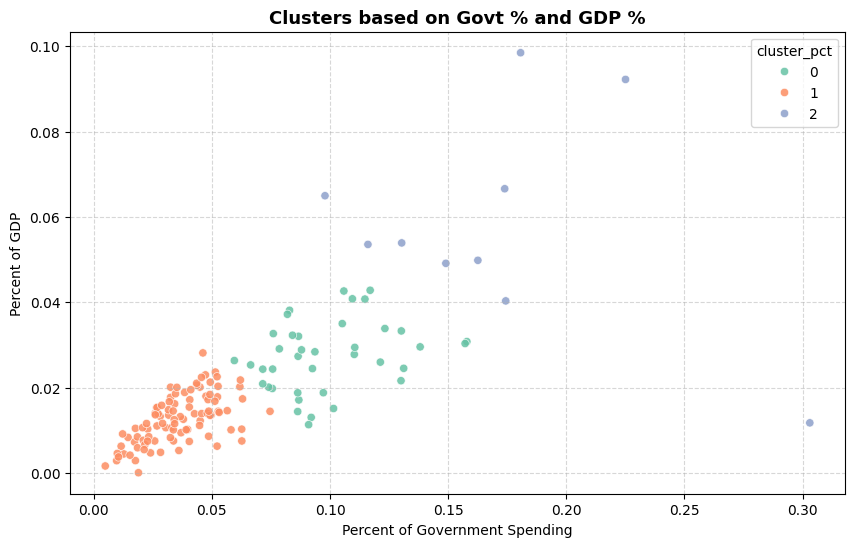

Percent of Government Spending                                \
                                     count      mean       std       min   
cluster_pct                                                                
0                                     39.0  0.098683  0.024125  0.059520   
1                                     99.0  0.035777  0.014549  0.004896   
2                                     10.0  0.171289  0.058725  0.097882   

                                                    Percent of GDP            \
                  25%       50%       75%       max          count      mean   
cluster_pct                                                                    
0            0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1            0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2            0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                         
                  std       min       25%       50%       75%       max  
cluster_pct                                                              
0            0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1            0.005681  0.000054  0.008393  0.013191  0.016752  0.028132  
2            0.024867  0.011742  0.049297  0.053729  0.066190  0.098470

In [36]:
kmeans_pct = KMeans(n_clusters=3, random_state=100, n_init=10)
df_2020['cluster_pct'] = kmeans_pct.fit_predict(scaled_pct)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_2020, x='Percent of Government Spending', y='Percent of GDP', hue='cluster_pct', palette='Set2', alpha=0.85)
plt.title('Clusters based on Govt % and GDP %', fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

display(df_2020.groupby('cluster_pct')[['Percent of Government Spending', 'Percent of GDP']].describe())

Unlike Part 2 which focused on absolute scale, this partition groups countries by structural budget prioritization. Cluster 1 contains countries with low relative military priority (3.5% of government budget), Cluster 0 represents countries with moderate structural priority (9.8% of government budget), and Cluster 2 comprises highly militarized economies (17.1% of government budget).

In this relative view, the United States is grouped into Cluster 0 (moderate structural priority). Although its absolute budget is massive, its military spending as a percentage of GDP (3.7%) and government budget (8.2%) is structurally comparable to other moderately prioritized nations, rather than being an extreme outlier.

**Comparison to Part 2:**
- **Scale vs. Ratio:** Part 2 clustered by absolute scale, making the US a single-member outlier due to its immense wealth and spending. Part 3 clusters by relative intensity, grouping the US with other nations that allocate a similar proportion of their resources to defense.
- **Distribution:** In Part 2, the vast majority of countries were compressed into a single low-spending cluster (Cluster 0). In Part 3, countries are more evenly distributed across low, moderate, and high structural priority profiles.

### **Question 2 - Part 4 (AI-Assisted Revision)**

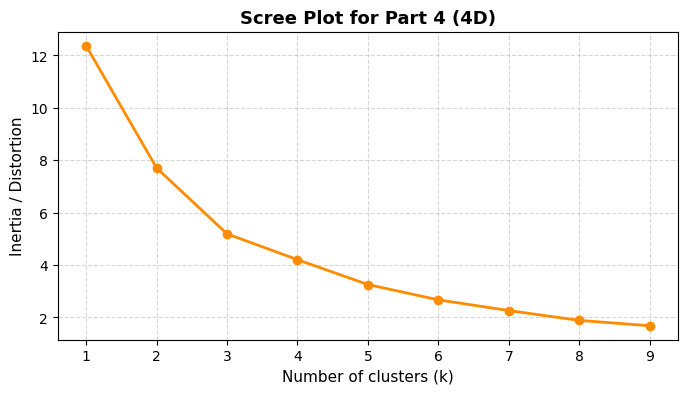

In [37]:
# Max-min normalize all four numeric variables
all_features = df_2020[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']]
scaled_all = scaler.fit_transform(all_features)

inertias_all = [KMeans(n_clusters=k, random_state=100, n_init=10).fit(scaled_all).inertia_ for k in range(1, 10)]

plt.figure(figsize=(8, 4))
plt.plot(range(1, 10), inertias_all, marker='o', color='darkorange', linewidth=2)
plt.xlabel('Number of clusters (k)', fontsize=11)
plt.ylabel('Inertia / Distortion', fontsize=11)
plt.title('Scree Plot for Part 4 (4D)', fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [38]:
kmeans_all = KMeans(n_clusters=4, random_state=100, n_init=10)
df_2020['cluster_all'] = kmeans_all.fit_predict(scaled_all)

display(df_2020.groupby('cluster_all')[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']].mean())

,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
cluster_all,,,,
0,15330.618681,612.677541,0.033280,0.016585
1,9073.543709,215.920971,0.123701,0.034105
2,4513.543790,70.290644,0.043199,0.012481
3,147964.582042,1875.150751,0.135351,0.062634


**Comparison to Parts 2 and 3:**

By incorporating all four variables, the 4D clustering model successfully bridges the gap between the absolute scale focus of Part 2 and the structural budget priority focus of Part 3. Instead of isolating the United States as a single-element outlier cluster due to its extreme absolute spending (as in Part 2) or blending it with hundreds of low-spending countries with similar priority ratios (as in Part 3), the multi-dimensional algorithm groups the US into Cluster 3 along with other high-scale and highly-prioritized nations. This gives more nuanced profiles that segment countries by balancing high absolute defense capability alongside significant internal domestic budget prioritizations.

### **Question 2 - Part 5 (AI-Assisted Revision)**

**K-Means Clustering - patterns identified**

- The K-Means algorithm effectively partitions countries based on overall spending scale vs. budget intensity scale.
- In Part 2, the United States belongs to an extreme outlier cluster due to its incredibly high absolute spending, while most other countries cluster closely together with low-to-moderate budgets.
- In Part 3, grouping on percentages of GDP and government spending segments countries by their relative policy priorities (e.g., highly militarized economies vs. those with lower proportional priorities).
- In Part 4, combining all factors yields multi-dimensional profiles that balance scale and intensity metrics.

### *Reflection on AI assistance

Collaborating with AI significantly enhanced this clustering assignment by establishing cohesive subplot shared-axes layouts, improving color-palette choices, and introducing robust logic. A prime example is transitioning from an exact country string search to a substring search (`.str.contains('United States')`), ensuring robust identification of `'United States of America'` across dataset variations. While the AI successfully automated tedious statistical group calculations and structured clean, repeatable workflows, it is inherently limited by its lack of execution context; it cannot inherently run and verify live plot boundaries or confirm the exact database headers without human oversight. The final solutions were verified by running every step sequentially, checking the output shapes, and plotting descriptive summaries to ensure that cluster categories reflect logical military spending scale and intensity partitions without formatting anomalies.